In [8]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


MIXED DATA SHAPE: (1000, 3)

ICA COMPONENTS
Recovered Shape: (1000, 3)

UNMIXING MATRIX
[[ 7.94423048 -3.57804843 -4.42573364]
 [ 0.61457474  1.33241074 -1.35175003]
 [-3.37446442  0.96121177  3.36117573]]

MIXING MATRIX
[[0.39965656 0.53762536 0.74245108]
 [0.17263335 0.81397082 0.55466136]
 [0.35186783 0.30697571 0.88428216]]


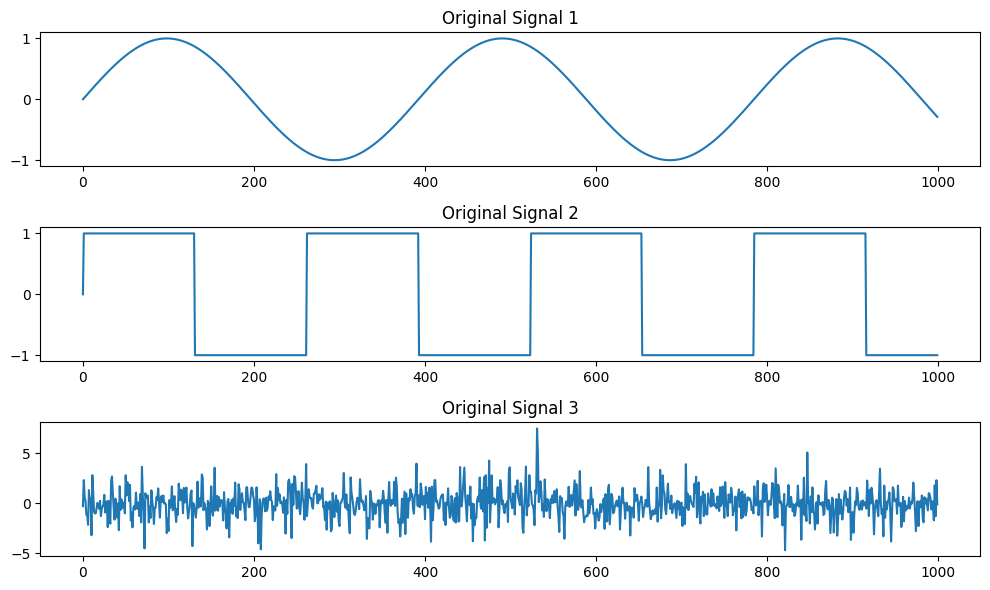

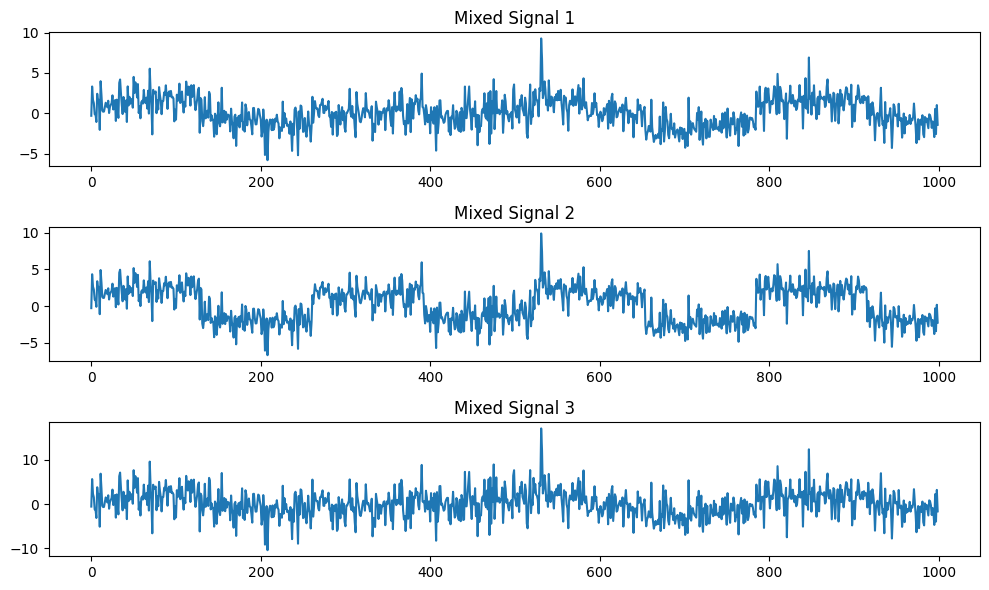

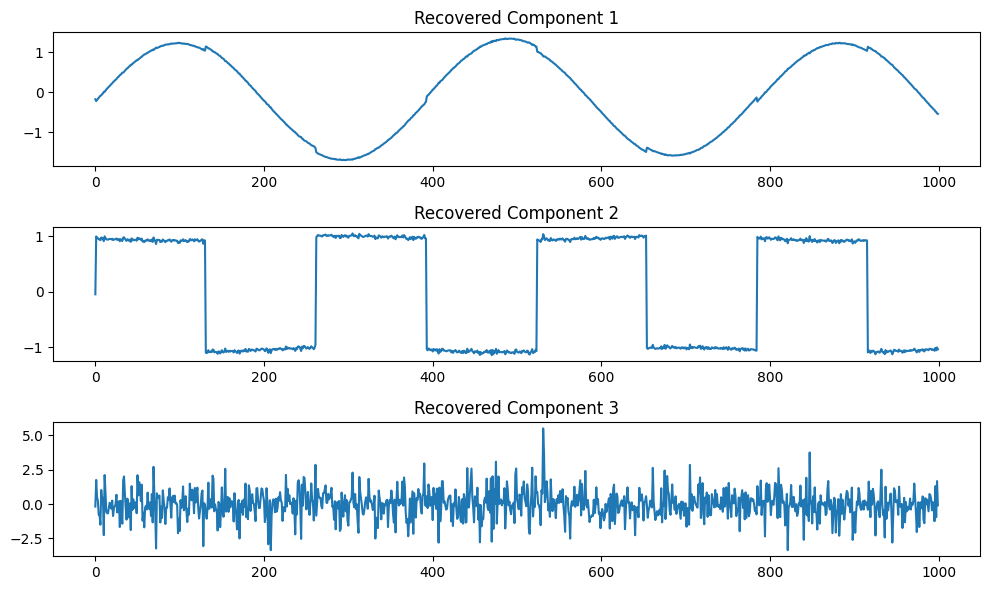


Reconstruction Error: 1.1060215727755629e-30


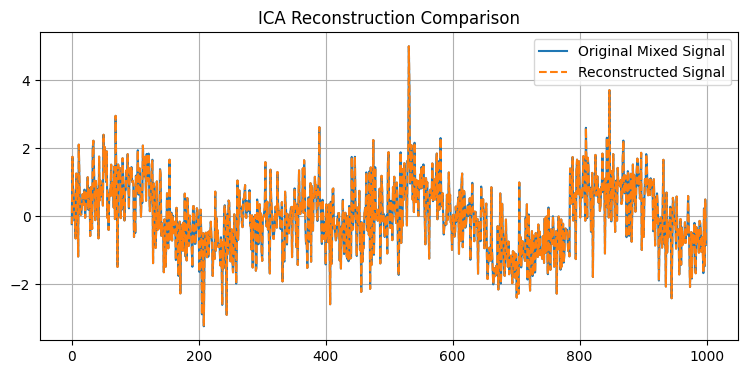

In [13]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import FastICA
from sklearn.preprocessing import StandardScaler

# 1. Generate independent signals
np.random.seed(42)

time = np.linspace(0, 8, 1000)

signal1 = np.sin(2 * time)

signal2 = np.sign(np.sin(3 * time))

signal3 = np.random.laplace(
    size=1000
)

# 2. Combine independent signals
S = np.c_[
    signal1,
    signal2,
    signal3
]

# 3. Mix the signals
A = np.array([
    [1, 1, 1],
    [0.5, 2, 1],
    [1.5, 1, 2]
])

X = np.dot(S, A.T)

print("MIXED DATA SHAPE:", X.shape)

# 4. Standardize mixed data
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# 5. Apply ICA
ica = FastICA(
    n_components=3,
    random_state=42,
    max_iter=1000,
    tol=0.001
)

S_recovered = ica.fit_transform(X_scaled)

# 6. Display results
print("\nICA COMPONENTS")

print("Recovered Shape:", S_recovered.shape)

print("\nUNMIXING MATRIX")

print(ica.components_)

print("\nMIXING MATRIX")

print(ica.mixing_)

# 7. Plot original signals
plt.figure(figsize=(10, 6))

for i in range(3):

    plt.subplot(3, 1, i + 1)

    plt.plot(S[:, i])

    plt.title(f"Original Signal {i+1}")

plt.tight_layout()
plt.show()

# 8. Plot mixed signals
plt.figure(figsize=(10, 6))

for i in range(3):

    plt.subplot(3, 1, i + 1)

    plt.plot(X[:, i])

    plt.title(f"Mixed Signal {i+1}")

plt.tight_layout()
plt.show()

# 9. Plot recovered independent components
plt.figure(figsize=(10, 6))

for i in range(3):

    plt.subplot(3, 1, i + 1)

    plt.plot(S_recovered[:, i])

    plt.title(f"Recovered Component {i+1}")

plt.tight_layout()
plt.show()

# 10. Reconstruct mixed data
X_reconstructed = ica.inverse_transform(
    S_recovered
)

reconstruction_error = np.mean(
    (X_scaled - X_reconstructed) ** 2
)

print(
    "\nReconstruction Error:",
    reconstruction_error
)

# 11. Display comparison
plt.figure(figsize=(9, 4))

plt.plot(
    X_scaled[:, 0],
    label="Original Mixed Signal"
)

plt.plot(
    X_reconstructed[:, 0],
    label="Reconstructed Signal",
    linestyle="--"
)

plt.title("ICA Reconstruction Comparison")

plt.legend()
plt.grid()
plt.show()